# Obesity Level Classification - Model Training

Training and evaluating 5 classifiers on the UCI obesity dataset

## 1. Install requirements

In [33]:
!pip install -r requirements.txt

## 2. Import libraries

In [35]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, classification_report)

SEED = 2026
TARGET = "NObeyesdad"
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

## 3. Load the dataset

In [37]:
df = pd.read_csv("data/raw/ObesityDataSet_raw_and_data_sinthetic.csv")
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
df.head()

Shape: (2111, 17)
Missing values: 0


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


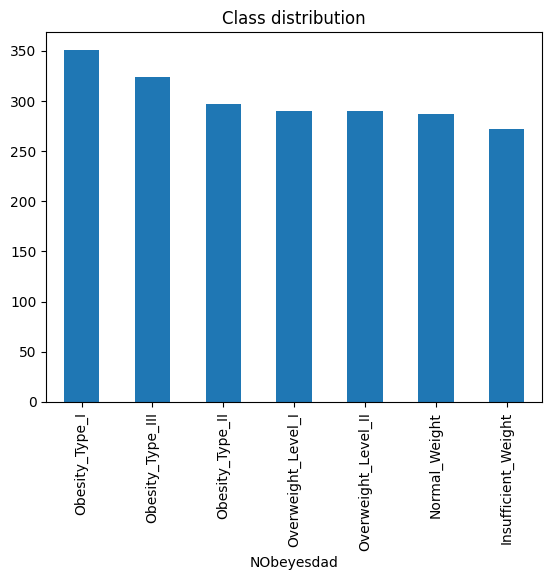

In [38]:
print(df[TARGET].value_counts())
df[TARGET].value_counts().plot(kind="bar", title="Class distribution")
plt.show()

## 4. Pre-processing

In [40]:
X = df.drop(columns=[TARGET])
encoder = LabelEncoder()
y = encoder.fit_transform(df[TARGET])
print("Classes:", list(encoder.classes_))

Classes: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1688, 16)  Test: (423, 16)


In [42]:
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

Numeric: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Categorical: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']


## 5. Evaluation function (6 metrics + confusion matrix)

In [44]:
results = {}

def evaluate(name, pipe):
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)
    scores = {
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1": f1_score(y_test, pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
    }
    results[name] = scores
    print(name)
    for k, v in scores.items():
        print(f"  {k}: {v:.4f}")

    cm = confusion_matrix(y_test, pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=encoder.classes_, yticklabels=encoder.classes_)
    plt.title(f"Confusion matrix - {name}")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.xticks(rotation=45, ha="right")
    plt.show()

    joblib.dump(pipe, MODEL_DIR / (name.lower().replace(" ", "_") + ".joblib"))

## 6. Model 1 - Logistic Regression

/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic Regression
  Accuracy: 0.8794
  AUC: 0.9879
  Precision: 0.8785
  Recall: 0.8794
  F1: 0.8782
  MCC: 0.8594


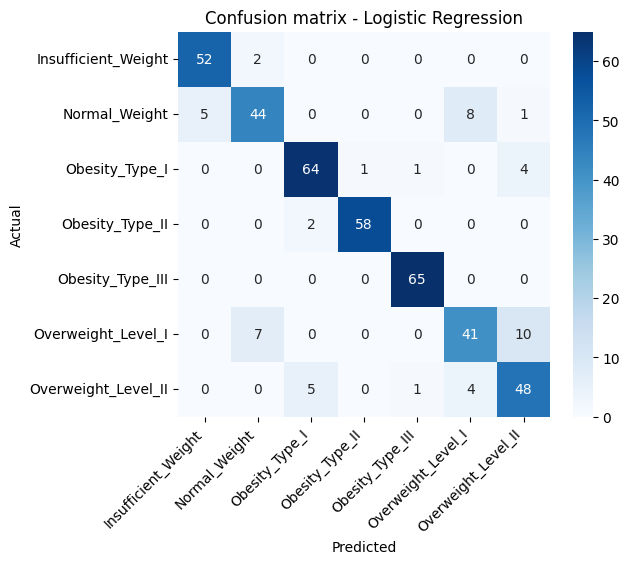

In [46]:
lr = Pipeline([("prep", make_preprocessor()),
               ("clf", LogisticRegression(max_iter=2000, random_state=SEED))])
lr.fit(X_train, y_train)
evaluate("Logistic Regression", lr)

## 7. Model 2 - Decision Tree

Decision Tree
  Accuracy: 0.9267
  AUC: 0.9562
  Precision: 0.9263
  Recall: 0.9267
  F1: 0.9264
  MCC: 0.9144


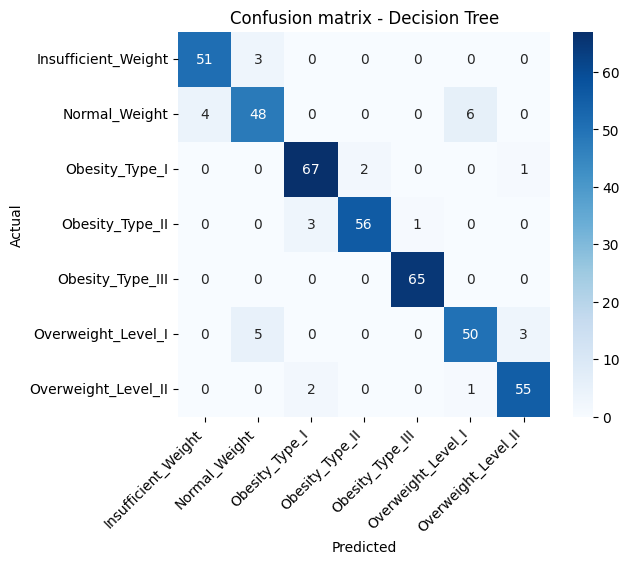

In [48]:
dt = Pipeline([("prep", make_preprocessor()),
               ("clf", DecisionTreeClassifier(max_depth=12, random_state=SEED))])
dt.fit(X_train, y_train)
evaluate("Decision Tree", dt)

## 8. Model 3 - K-Nearest Neighbors

KNN
  Accuracy: 0.8463
  AUC: 0.9677
  Precision: 0.8516
  Recall: 0.8463
  F1: 0.8335
  MCC: 0.8240


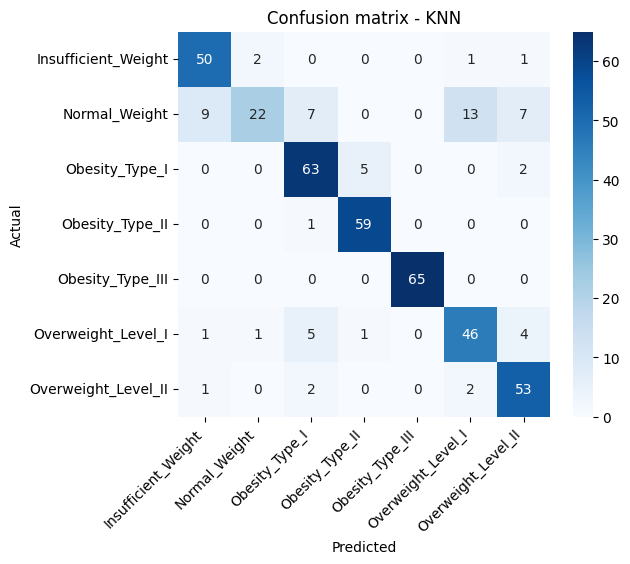

In [50]:
knn = Pipeline([("prep", make_preprocessor()),
                ("clf", KNeighborsClassifier(n_neighbors=7, weights="distance"))])
knn.fit(X_train, y_train)
evaluate("KNN", knn)

## 9. Model 4 - Gaussian Naive Bayes

Naive Bayes
  Accuracy: 0.5626
  AUC: 0.8894
  Precision: 0.5887
  Recall: 0.5626
  F1: 0.5122
  MCC: 0.5098


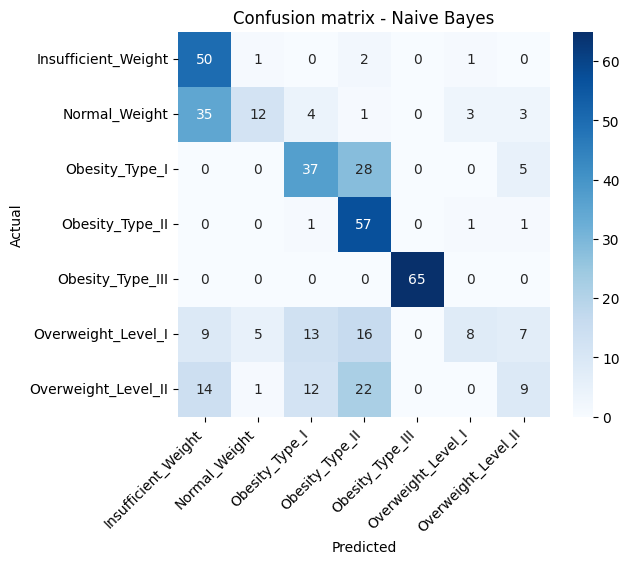

In [52]:
nb = Pipeline([("prep", make_preprocessor()),
               ("clf", GaussianNB())])
nb.fit(X_train, y_train)
evaluate("Naive Bayes", nb)

## 10. Model 5 - Support Vector Machine

Support Vector Machine
  Accuracy: 0.9574
  AUC: 0.9973
  Precision: 0.9582
  Recall: 0.9574
  F1: 0.9576
  MCC: 0.9504


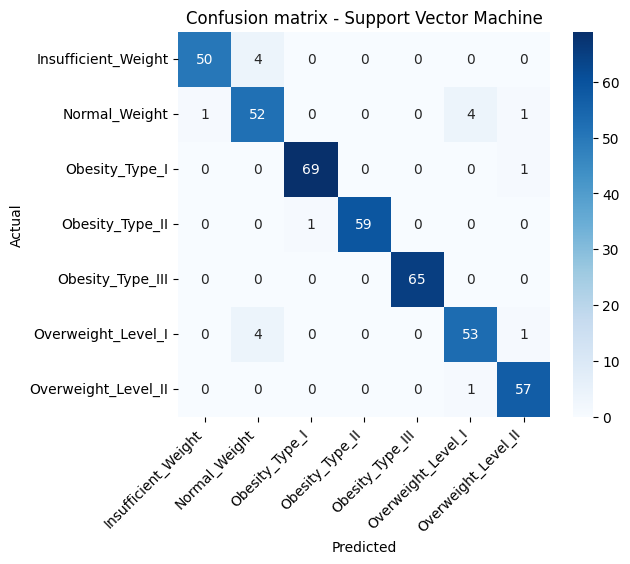

In [54]:
svm = Pipeline([("prep", make_preprocessor()),
                ("clf", SVC(kernel="rbf", C=5.0, probability=True, random_state=SEED))])
svm.fit(X_train, y_train)
evaluate("Support Vector Machine", svm)

## 11. Comparison of all 5 models

In [56]:
table = pd.DataFrame(results).T.round(4)
table

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8794,0.9879,0.8785,0.8794,0.8782,0.8594
Decision Tree,0.9267,0.9562,0.9263,0.9267,0.9264,0.9144
KNN,0.8463,0.9677,0.8516,0.8463,0.8335,0.8240
Naive Bayes,0.5626,0.8894,0.5887,0.5626,0.5122,0.5098
Support Vector Machine,0.9574,0.9973,0.9582,0.9574,0.9576,0.9504


In [57]:
print(classification_report(y_test, svm.predict(X_test), target_names=encoder.classes_))

                     precision    recall  f1-score   support

Insufficient_Weight       0.98      0.93      0.95        54
      Normal_Weight       0.87      0.90      0.88        58
     Obesity_Type_I       0.99      0.99      0.99        70
    Obesity_Type_II       1.00      0.98      0.99        60
   Obesity_Type_III       1.00      1.00      1.00        65
 Overweight_Level_I       0.91      0.91      0.91        58
Overweight_Level_II       0.95      0.98      0.97        58

           accuracy                           0.96       423
          macro avg       0.96      0.96      0.96       423
       weighted avg       0.96      0.96      0.96       423



## 12. Save encoder and metrics

In [59]:
joblib.dump(encoder, MODEL_DIR / "label_encoder.joblib")
(MODEL_DIR / "metrics.json").write_text(json.dumps(table.to_dict(orient="index"), indent=2))
!ls -l model

total 784
-rw-r--r--. 1 s2026ak05516 s2026ak05516  29235 Nov  8 14:57 decision_tree.joblib
-rw-r--r--. 1 s2026ak05516 s2026ak05516 438182 Nov  8 14:57 knn.joblib
-rw-r--r--. 1 s2026ak05516 s2026ak05516    682 Nov  8 14:57 label_encoder.joblib
-rw-r--r--. 1 s2026ak05516 s2026ak05516   7921 Nov  8 14:57 logistic_regression.joblib
-rw-r--r--. 1 s2026ak05516 s2026ak05516    764 Nov  8 14:57 metrics.json
-rw-r--r--. 1 s2026ak05516 s2026ak05516   9585 Nov  8 14:57 naive_bayes.joblib
-rw-r--r--. 1 s2026ak05516 s2026ak05516 301469 Nov  8 14:57 support_vector_machine.joblib
